# 1.1. Задача

Суть задачі та практичне застосування:
Мета роботи — створити модуль перетворення запитів природною мовою на SQL-запити (Text-to-SQL) для довільної бази даних користувача на СУБД SQLite. Користувач підключає власний файл БД (.sqlite / .db), а система автоматично дістає з нього структуру таблиць, генерує SQL-запит і одразу запускає його у вбудованій СУБД SQLite (sqlite3) для перевірки. Якщо при виконанні виникає помилка, текст помилки повертається моделі, щоб вона сама виправила запит і віддала правильний результат. На практиці це можна вбудувати в локальний чат-бот, адмін-панель або програму для аналізу даних, щоб працювати з таблицями без знання SQL.

Користувачі, вхід і вихід:

Користувач: аналітики, менеджери або розробники, яким потрібно швидко витягувати дані з власних баз SQLite без ручного написання SQL-коду.

На вхід подається: схема таблиць користувацької БД (CREATE TABLE ..., зчитана з sqlite_master), запит користувача українською або англійською мовою, а у разі невдалого запуску — текст помилки від SQLite для виправлення.

На виході: лише чистий SQL-запит у діалекті SQLite (без зайвого тексту й обгорток), який успішно проходить перевірку запуском у БД.

Чому потрібне саме донавчання (SFT), а не лише промпт чи RAG:

Чому недостатньо промпту: базові компактні моделі без донавчання часто плутають діалекти SQL (використовують конструкції з PostgreSQL чи MS SQL, які падають у SQLite), додають текстові пояснення замість чистого коду, гірше розуміють запити українською мовою до англомовних таблиць і не вміють коректно виправляти свій запит за текстом помилки від SQLite.

Чому не підходить RAG: RAG потрібен для пошуку шматків тексту у великих документах, а тут схема таблиць користувача одразу й повністю береться з sqlite_master. Головна складність — не знайти текст, а правильно скласти синтаксис SQLite, поєднати таблиці через JOIN та відреагувати на помилку виконання, чого модель навчається саме під час SFT.

# 1.2 Модель і дані

1. **Модель:**
Обрано модель `Qwen/Qwen2.5-Coder-3B-Instruct` (3,12 млрд параметрів) із донавчанням методом QLoRA (4-бітна квантизація NF4 із подвійною квантизацією та обчисленнями у `float16`, `r=16`, `lora_alpha=32`).

* **Чому Instruct і Coder:** версія `Coder` попередньо натренована на великих корпусах програмного коду та SQL (краще будує `JOIN`, підзапити, агрегації та DDL-конструкції), а `Instruct` підтримує багатоходовий діалоговий формат (`system` / `user` / `assistant`), необхідний для ітеративного виправлення помилок за повідомленнями від `sqlite3`.
* **Чому 3B із QLoRA:** у 4-бітному поданні базова модель займає близько 2.3 ГБ відеопам'яті, що дозволяє безпечно виконувати повний цикл SFT-навчання з градієнтами та активаціями на безкоштовній GPU NVIDIA T4 (15 ГБ VRAM, пікове споживання під час тренування склало 13.59 ГБ) без ризику переповнення системної оперативної пам'яті Colab, зберігаючи при цьому високу точність генерації SQLite-запитів.

Чому 7B із QLoRA: у 4-бітній квантизації модель займає близько 6.5–7.5 ГБ відеопам'яті (вільно вміщується у 15 ГБ на безкоштовній GPU T4 у Google Colab) і дає значно точніший SQL, ніж легші моделі.

2. Дані:Оскільки відкриті Text-to-SQL датасети містять переважно англомовні SELECT-запити і майже не охоплюють тригери, індекси та виправлення помилок виконання у SQLite, сформовано гібридний набір на 2 000 прикладів (кожний запис автоматично перевірено виконанням у вбудованій СУБД sqlite3):

gretelai/synthetic_text_to_sql (Hugging Face, ліцензія Apache 2.0) — 800 прикладів (сучасні бізнес-схеми зі складними JOIN, агрегаціями та підзапитами, відфільтровані на сумісність із SQLite).

NumbersStation/NSText2SQL (Hugging Face, ліцензія Apache 2.0) — 400 прикладів (додаткові схеми БД із різних предметних областей, перевірені у sqlite3).

Власна спеціалізована вибірка — 800 прикладів, сформована за допомогою шаблонів та синтезу з обов'язковою валідацією кожного запиту в sqlite3:

300 запитів українською мовою на вибірку та аналітику;

200 прикладів на DDL-конструкції SQLite (CREATE TRIGGER, CREATE VIEW, CREATE INDEX, ALTER TABLE);

100 прикладів на зміну даних (INSERT, UPDATE, DELETE, ON CONFLICT);

200 двокрокових діалогів виправлення помилок за реальним повідомленням винятку від sqlite3.

Формат даних: діалоговий формат messages (system, user, assistant).

3. Поділ даних:Після перемішування (seed=42) 2 000 прикладів розділено на три неперетинні вибірки:

train: 1 600 прикладів (80%) — для тренування QLoRA-адаптера;

validation: 200 прикладів (10%) — для контролю eval_loss під час навчання;

test: 200 прикладів (10%) — ізольована контрольна вибірка (включно з новими українськими схемами БД, тригерами та діалогами виправлення, яких не було у train) для оцінки до та після донавчання.

# Підготовка середивоща

Імпортуємо встановлені бібліотеки та фіксуємо seed.
Фіксація seed потрібна для того, щоб усі випадкові процеси були відтворюваними під час кожного запуску ноутбука.



In [1]:
import json
import random
import torch
import pandas as pd
from huggingface_hub import notebook_login
import re
import time
from datasets import Dataset, load_dataset
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

set_seed(42)
random.seed(42)

#Блок 1. Завантаження відкритих датасетів


In [2]:
import sqlite3

raw_gretel = load_dataset("gretelai/synthetic_text_to_sql", split="train")
raw_scc = load_dataset("b-mc2/sql-create-context", split="train")

print(f"Завантажено gretelai/synthetic_text_to_sql: {len(raw_gretel)} записів")
print(f"Завантажено b-mc2/sql-create-context: {len(raw_scc)} записів")

README.md:   0%|          | 0.00/8.19k [00:00<?, ?B/s]

synthetic_text_to_sql_train.snappy.parqu(…): reconstructing file:   0%|          |  0.00B / 32.4MB            

synthetic_text_to_sql_train.snappy.parqu(…): downloading bytes:           |  0.00B            

synthetic_text_to_sql_test.snappy.parque(…): reconstructing file:   0%|          |  0.00B / 1.90MB            

synthetic_text_to_sql_test.snappy.parque(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

... (2 outputs left out)

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

Завантажено gretelai/synthetic_text_to_sql: 100000 записів
Завантажено b-mc2/sql-create-context: 78577 записів


# Блок 2. Валідація та фільтрація відкритих даних у SQLite

In [3]:
def check_sqlite_execution(schema_sql: str, target_sql: str, seed_sql: str = ""):
    """Перевіряє синтаксис і виконання SQL-запиту або DDL у реальній БД SQLite в пам'яті."""
    conn = sqlite3.connect(":memory:")
    try:
        cur = conn.cursor()
        cur.executescript(schema_sql)
        if seed_sql:
            cur.executescript(seed_sql)
        upper_sql = target_sql.strip().upper()
        if upper_sql.startswith(("SELECT", "WITH")):
            cur.execute(target_sql)
            rows = cur.fetchall()
            return True, None, rows
        else:
            cur.executescript(target_sql)
            return True, None, []
    except Exception as e:
        return False, str(e), None
    finally:
        conn.close()

# 1. Фільтрація gretelai/synthetic_text_to_sql (800 прикладів)
gretel_samples = []
for row in raw_gretel.shuffle(seed=42):
    schema = row["sql_context"].strip()
    question = row["sql_prompt"].strip()
    sql = row["sql"].strip().rstrip(";") + ";"
    if len(schema) > 1000 or len(sql) > 500:
        continue
    ok, _, _ = check_sqlite_execution(schema, sql)
    if ok:
        gretel_samples.append({
            "source": "gretelai",
            "category": row.get("sql_task_type", "select"),
            "schema": schema,
            "question": question,
            "gold_sql": sql,
            "seed_sql": "",
        })
    if len(gretel_samples) >= 800:
        break

# 2. Фільтрація b-mc2/sql-create-context (400 прикладів)
ns_samples = []
seen_questions = {x["question"] for x in gretel_samples}
for row in raw_scc.shuffle(seed=42):
    schema = row["context"].strip()
    question = row["question"].strip()
    sql = row["answer"].strip().rstrip(";") + ";"
    if question in seen_questions or len(schema) > 1000 or len(sql) > 500:
        continue
    ok, _, _ = check_sqlite_execution(schema, sql)
    if ok:
        seen_questions.add(question)
        ns_samples.append({
            "source": "sql_create_context",
            "category": "select",
            "schema": schema,
            "question": question,
            "gold_sql": sql,
            "seed_sql": "",
        })
    if len(ns_samples) >= 400:
        break

print(f"Відвалідовано gretelai: {len(gretel_samples)} | sql-create-context: {len(ns_samples)}")

Відвалідовано gretelai: 800 | sql-create-context: 400


# Блок 3. Формування власного датасету (українська мова, DDL, тригери)

In [4]:
DOMAIN_SCHEMAS = [
    {
        "domain": "shop",
        "schema": (
            "CREATE TABLE customers (id INTEGER PRIMARY KEY, name TEXT, city TEXT, segment TEXT, registered_at TEXT);\n"
            "CREATE TABLE products (id INTEGER PRIMARY KEY, title TEXT, category TEXT, price REAL, stock INTEGER);\n"
            "CREATE TABLE orders (id INTEGER PRIMARY KEY, customer_id INTEGER, product_id INTEGER, qty INTEGER, total REAL, status TEXT, order_date TEXT);\n"
            "CREATE TABLE audit_log (id INTEGER PRIMARY KEY, entity TEXT, entity_id INTEGER, action TEXT, created_at TEXT);"
        ),
        "seed": (
            "INSERT INTO customers VALUES (1,'Олена Коваль','Київ','VIP','2026-01-10'),(2,'Ігор Мельник','Львів','Regular','2026-02-15'),(3,'Анна Бондар','Київ','VIP','2026-03-01');\n"
            "INSERT INTO products VALUES (1,'Ноутбук Pro','Електроніка',42000,4),(2,'Миша бездротова','Електроніка',1200,25),(3,'Стіл офісний','Меблі',6500,2);\n"
            "INSERT INTO orders VALUES (1,1,1,1,42000,'delivered','2026-04-01'),(2,2,2,2,2400,'delivered','2026-04-05'),(3,3,3,1,6500,'cancelled','2026-04-10');"
        ),
    },
    {
        "domain": "university",
        "schema": (
            "CREATE TABLE students (id INTEGER PRIMARY KEY, full_name TEXT, group_code TEXT, enrollment_year INTEGER, scholarship REAL);\n"
            "CREATE TABLE courses (id INTEGER PRIMARY KEY, title TEXT, credits INTEGER, teacher TEXT);\n"
            "CREATE TABLE grades (id INTEGER PRIMARY KEY, student_id INTEGER, course_id INTEGER, score INTEGER, exam_date TEXT);\n"
            "CREATE TABLE grade_history (id INTEGER PRIMARY KEY, grade_id INTEGER, old_score INTEGER, new_score INTEGER, changed_at TEXT);"
        ),
        "seed": (
            "INSERT INTO students VALUES (1,'Альберт Ренькас','ІПЗ-23-5',2023,2000),(2,'Данііл Козак','ІПЗ-23-5',2023,0),(3,'Марія Савченко','КН-23-1',2023,2500);\n"
            "INSERT INTO courses VALUES (1,'Бази даних',5,'Петренко'),(2,'Штучний інтелект',4,'Сидоренко');\n"
            "INSERT INTO grades VALUES (1,1,1,95,'2026-05-20'),(2,2,1,88,'2026-05-20'),(3,3,2,91,'2026-05-22');"
        ),
    },
    {
        "domain": "fitness",
        "schema": (
            "CREATE TABLE members (id INTEGER PRIMARY KEY, name TEXT, phone TEXT, plan TEXT, active INTEGER);\n"
            "CREATE TABLE workouts (id INTEGER PRIMARY KEY, member_id INTEGER, exercise TEXT, weight_kg REAL, reps INTEGER, workout_date TEXT);\n"
            "CREATE TABLE trainers (id INTEGER PRIMARY KEY, name TEXT, specialization TEXT, hourly_rate REAL);\n"
            "CREATE TABLE alerts (id INTEGER PRIMARY KEY, member_id INTEGER, message TEXT, created_at TEXT);"
        ),
        "seed": (
            "INSERT INTO members VALUES (1,'Максим','0971112233','VIP',1),(2,'Олег','0672223344','Basic',1),(3,'Тарас','0503334455','VIP',0);\n"
            "INSERT INTO workouts VALUES (1,1,'Жим лежачи',110,6,'2026-10-01'),(2,1,'Підтягування',20,10,'2026-10-03'),(3,2,'Присідання',90,8,'2026-10-04');\n"
            "INSERT INTO trainers VALUES (1,'Андрій','Силовий тренінг',500),(2,'Вікторія','Кросфіт',450);"
        ),
    },
    {
        "domain": "bank",
        "schema": (
            "CREATE TABLE accounts (id INTEGER PRIMARY KEY, owner_name TEXT, iban TEXT, balance REAL, currency TEXT, status TEXT);\n"
            "CREATE TABLE transactions (id INTEGER PRIMARY KEY, account_id INTEGER, amount REAL, tx_type TEXT, created_at TEXT);\n"
            "CREATE TABLE security_log (id INTEGER PRIMARY KEY, account_id INTEGER, reason TEXT, logged_at TEXT);"
        ),
        "seed": (
            "INSERT INTO accounts VALUES (1,'Дмитро Ткач','UA111',54000,'UAH','active'),(2,'Наталія Лисенко','UA222',1200,'USD','active'),(3,'Сергій Мороз','UA333',0,'UAH','blocked');\n"
            "INSERT INTO transactions VALUES (1,1,15000,'deposit','2026-11-01'),(2,1,-3200,'withdraw','2026-11-05'),(3,2,500,'deposit','2026-11-10');"
        ),
    },
    {
        "domain": "library_test",
        "schema": (
            "CREATE TABLE books (id INTEGER PRIMARY KEY, title TEXT, author TEXT, genre TEXT, copies_available INTEGER);\n"
            "CREATE TABLE loans (id INTEGER PRIMARY KEY, book_id INTEGER, reader_name TEXT, loan_date TEXT, returned INTEGER);\n"
            "CREATE TABLE library_audit (id INTEGER PRIMARY KEY, book_id INTEGER, event TEXT, event_time TEXT);"
        ),
        "seed": (
            "INSERT INTO books VALUES (1,'Кобзар','Тарас Шевченко','Поезія',3),(2,'Тіні забутих предків','Михайло Коцюбинський','Проза',0),(3,'Чистий код','Роберт Мартін','ІТ',2);\n"
            "INSERT INTO loans VALUES (1,2,'Іван Франко','2026-10-15',0),(2,3,'Леся Українка','2026-09-10',1);"
        ),
    },
]

TEMPLATES_BY_DOMAIN = {
    "shop": [
        ("select", "Покажи всіх клієнтів з міста {city} у сегменті {seg}.", "SELECT * FROM customers WHERE city = '{city}' AND segment = '{seg}';"),
        ("select", "Яка загальна сума замовлень зі статусом {st}?", "SELECT SUM(total) FROM orders WHERE status = '{st}';"),
        ("select", "Виведи топ-{lim} найдорожчих товарів у категорії {cat}.", "SELECT title, price FROM products WHERE category = '{cat}' ORDER BY price DESC LIMIT {lim};"),
        ("select", "Порахуй кількість замовлень кожного клієнта, виведи ім'я та кількість.", "SELECT c.name, COUNT(o.id) FROM customers c LEFT JOIN orders o ON c.id = o.customer_id GROUP BY c.id, c.name;"),
        ("select", "Знайди товари, залишок яких на складі менший за {qty} одиниць.", "SELECT title, stock FROM products WHERE stock < {qty};"),
        ("select", "Покажи виручку по кожному місяцю 2026 року для доставлених замовлень.", "SELECT strftime('%Y-%m', order_date) AS month, SUM(total) FROM orders WHERE status = 'delivered' AND strftime('%Y', order_date) = '2026' GROUP BY month;"),
        ("trigger", "Створи тригер trg_log_new_order_{idx}, який після вставки нового замовлення в orders додає запис у audit_log з entity='order', id замовлення, action='INSERT' і поточним часом.",
         "CREATE TRIGGER trg_log_new_order_{idx} AFTER INSERT ON orders FOR EACH ROW BEGIN INSERT INTO audit_log (entity, entity_id, action, created_at) VALUES ('order', NEW.id, 'INSERT', datetime('now')); END;"),
        ("trigger", "Створи тригер trg_prevent_negative_stock_{idx}, який перед оновленням stock у таблиці products скасовує операцію з помилкою 'Negative stock', якщо нове значення менше 0.",
         "CREATE TRIGGER trg_prevent_negative_stock_{idx} BEFORE UPDATE OF stock ON products FOR EACH ROW WHEN NEW.stock < 0 BEGIN SELECT RAISE(ABORT, 'Negative stock'); END;"),
        ("trigger", "Створи тригер trg_decrease_stock_{idx}, який після додавання рядка в orders зменшує stock відповідного товару в products на значення NEW.qty.",
         "CREATE TRIGGER trg_decrease_stock_{idx} AFTER INSERT ON orders FOR EACH ROW BEGIN UPDATE products SET stock = stock - NEW.qty WHERE id = NEW.product_id; END;"),
        ("ddl", "Створи індекс idx_orders_customer_status_{idx} по колонках customer_id та status у таблиці orders.",
         "CREATE INDEX idx_orders_customer_status_{idx} ON orders (customer_id, status);"),
        ("ddl", "Створи представлення view_vip_customers_{idx}, яке містить id, name та city всіх VIP-клієнтів.",
         "CREATE VIEW view_vip_customers_{idx} AS SELECT id, name, city FROM customers WHERE segment = 'VIP';"),
        ("dml", "Збільш ціну всіх товарів у категорії {cat} на 10 відсотків.",
         "UPDATE products SET price = price * 1.10 WHERE category = '{cat}';"),
        ("dml", "Видали всі скасовані замовлення (status = 'cancelled'), створені до '2026-05-01'.",
         "DELETE FROM orders WHERE status = 'cancelled' AND order_date < '2026-05-01';"),
    ],
    "university": [
        ("select", "Виведи всіх студентів групи {grp}, відсортованих за прізвищем.", "SELECT * FROM students WHERE group_code = '{grp}' ORDER BY full_name ASC;"),
        ("select", "Порахуй середній бал кожного студента по всіх складених іспитах.", "SELECT s.full_name, AVG(g.score) FROM students s JOIN grades g ON s.id = g.student_id GROUP BY s.id, s.full_name;"),
        ("select", "Покажи студентів, які мають бал вище {score} з дисципліни '{subj}'.", "SELECT s.full_name, g.score FROM students s JOIN grades g ON s.id = g.student_id JOIN courses c ON c.id = g.course_id WHERE c.title = '{subj}' AND g.score > {score};"),
        ("select", "Скільки кредитів загалом читає викладач {teacher}?", "SELECT SUM(credits) FROM courses WHERE teacher = '{teacher}';"),
        ("trigger", "Створи тригер trg_grade_audit_{idx}, який після зміни оцінки score в таблиці grades записує grade_id, стару оцінку, нову оцінку та поточний час у grade_history.",
         "CREATE TRIGGER trg_grade_audit_{idx} AFTER UPDATE OF score ON grades FOR EACH ROW WHEN OLD.score <> NEW.score BEGIN INSERT INTO grade_history (grade_id, old_score, new_score, changed_at) VALUES (NEW.id, OLD.score, NEW.score, datetime('now')); END;"),
        ("trigger", "Створи тригер trg_check_score_{idx}, який перед вставкою в grades забороняє запис із помилкою 'Invalid score', якщо score < 0 або score > 100.",
         "CREATE TRIGGER trg_check_score_{idx} BEFORE INSERT ON grades FOR EACH ROW WHEN NEW.score < 0 OR NEW.score > 100 BEGIN SELECT RAISE(ABORT, 'Invalid score'); END;"),
        ("ddl", "Створи унікальний індекс idx_student_course_{idx} на таблиці grades по парах (student_id, course_id).",
         "CREATE UNIQUE INDEX idx_student_course_{idx} ON grades (student_id, course_id);"),
        ("ddl", "Створи представлення view_scholarship_students_{idx} для студентів зі стипендією понад 0.",
         "CREATE VIEW view_scholarship_students_{idx} AS SELECT full_name, group_code, scholarship FROM students WHERE scholarship > 0;"),
        ("dml", "Признач стипендію 2200 грн усім студентам групи {grp}, у яких зараз стипендія 0.",
         "UPDATE students SET scholarship = 2200 WHERE group_code = '{grp}' AND scholarship = 0;"),
    ],
    "fitness": [
        ("select", "Покажи всіх активних учасників клубу з тарифом {plan}.", "SELECT name, phone FROM members WHERE active = 1 AND plan = '{plan}';"),
        ("select", "Яка максимальна вага у вправі '{ex}' зафіксована в базі?", "SELECT MAX(weight_kg) FROM workouts WHERE exercise = '{ex}';"),
        ("select", "Виведи загальний тоннаж (суму weight_kg * reps) для кожного учасника за весь час.", "SELECT m.name, SUM(w.weight_kg * w.reps) AS total_tonnage FROM members m JOIN workouts w ON m.id = w.member_id GROUP BY m.id, m.name;"),
        ("trigger", "Створи тригер trg_heavy_lift_alert_{idx}, який після додавання тренування в workouts з вагою понад 100 кг додає сповіщення в таблицю alerts.",
         "CREATE TRIGGER trg_heavy_lift_alert_{idx} AFTER INSERT ON workouts FOR EACH ROW WHEN NEW.weight_kg > 100 BEGIN INSERT INTO alerts (member_id, message, created_at) VALUES (NEW.member_id, 'New lift over 100kg', datetime('now')); END;"),
        ("ddl", "Створи індекс idx_workouts_member_date_{idx} для швидкого пошуку тренувань за member_id та workout_date.",
         "CREATE INDEX idx_workouts_member_date_{idx} ON workouts (member_id, workout_date);"),
        ("ddl", "Створи представлення view_active_vip_{idx} зі списком активних клієнтів тарифу VIP.",
         "CREATE VIEW view_active_vip_{idx} AS SELECT id, name, phone FROM members WHERE active = 1 AND plan = 'VIP';"),
    ],
    "bank": [
        ("select", "Покажи всі активні рахунки у валюті {curr} з балансом більше {bal}.", "SELECT owner_name, iban, balance FROM accounts WHERE status = 'active' AND currency = '{curr}' AND balance > {bal};"),
        ("select", "Порахуй загальну суму поповнень (tx_type = 'deposit') по кожному рахунку.", "SELECT account_id, SUM(amount) FROM transactions WHERE tx_type = 'deposit' GROUP BY account_id;"),
        ("trigger", "Створи тригер trg_block_overdraft_{idx}, який перед списанням або оновленням balance в accounts кидає помилку 'Insufficient funds', якщо новий баланс від'ємний.",
         "CREATE TRIGGER trg_block_overdraft_{idx} BEFORE UPDATE OF balance ON accounts FOR EACH ROW WHEN NEW.balance < 0 BEGIN SELECT RAISE(ABORT, 'Insufficient funds'); END;"),
        ("trigger", "Створи тригер trg_large_tx_log_{idx}, який після вставки транзакції на суму понад 10000 записує подію в security_log.",
         "CREATE TRIGGER trg_large_tx_log_{idx} AFTER INSERT ON transactions FOR EACH ROW WHEN ABS(NEW.amount) > 10000 BEGIN INSERT INTO security_log (account_id, reason, logged_at) VALUES (NEW.account_id, 'Large transaction', datetime('now')); END;"),
        ("ddl", "Створи унікальний індекс idx_accounts_iban_{idx} по колонці iban у таблиці accounts.",
         "CREATE UNIQUE INDEX idx_accounts_iban_{idx} ON accounts (iban);"),
    ],
    "library_test": [
        ("select", "Покажи всі книги жанру '{genre}', які зараз є в наявності (copies_available > 0).", "SELECT title, author, copies_available FROM books WHERE genre = '{genre}' AND copies_available > 0;"),
        ("select", "Хто з читачів досі не повернув книги (returned = 0)? Виведи назву книги та ім'я читача.", "SELECT b.title, l.reader_name FROM books b JOIN loans l ON b.id = l.book_id WHERE l.returned = 0;"),
        ("trigger", "Створи тригер trg_loan_audit_{idx}, який після видачі книги (INSERT у loans) записує book_id, подію 'LOAN' та поточний час у library_audit.",
         "CREATE TRIGGER trg_loan_audit_{idx} AFTER INSERT ON loans FOR EACH ROW BEGIN INSERT INTO library_audit (book_id, event, event_time) VALUES (NEW.book_id, 'LOAN', datetime('now')); END;"),
        ("ddl", "Створи індекс idx_books_author_{idx} по колонці author у таблиці books.",
         "CREATE INDEX idx_books_author_{idx} ON books (author);"),
        ("ddl", "Створи представлення view_unreturned_books_{idx} з неповернутими позиками.",
         "CREATE VIEW view_unreturned_books_{idx} AS SELECT book_id, reader_name, loan_date FROM loans WHERE returned = 0;"),
    ],
}

params_pool = {
    "city": ["Київ", "Львів", "Житомир", "Одеса", "Харків"],
    "seg": ["VIP", "Regular"],
    "st": ["delivered", "pending", "cancelled"],
    "lim": [3, 5, 10],
    "cat": ["Електроніка", "Меблі", "Одяг", "Книги"],
    "qty": [3, 5, 10, 15],
    "grp": ["ІПЗ-23-5", "КН-23-1", "ПІ-23-2"],
    "score": [75, 80, 90],
    "subj": ["Бази даних", "Штучний інтелект", "Алгоритми"],
    "teacher": ["Петренко", "Сидоренко", "Коваленко"],
    "plan": ["VIP", "Basic"],
    "ex": ["Жим лежачи", "Підтягування", "Присідання"],
    "curr": ["UAH", "USD", "EUR"],
    "bal": [1000, 5000, 20000],
    "genre": ["Поезія", "Проза", "ІТ", "Історія"],
}

custom_train_val = []
custom_test_isolated = []
idx_counter = 1

# 40 ізольованих прикладів (домен library_test — не потрапляє у train/val)
lib_info = [d for d in DOMAIN_SCHEMAS if d["domain"] == "library_test"][0]
while len(custom_test_isolated) < 40:
    cat, q_tpl, sql_tpl = random.choice(TEMPLATES_BY_DOMAIN["library_test"])
    subs = {k: random.choice(v) for k, v in params_pool.items()}
    subs["idx"] = idx_counter
    idx_counter += 1
    q, sql = q_tpl.format(**subs), sql_tpl.format(**subs)
    ok, _, _ = check_sqlite_execution(lib_info["schema"], sql, lib_info["seed"])
    if ok:
        custom_test_isolated.append({
            "source": "custom_uk", "category": cat, "schema": lib_info["schema"],
            "question": q, "gold_sql": sql, "seed_sql": lib_info["seed"],
        })

# 760 прикладів для train/val по інших доменах
other_domains = [d for d in DOMAIN_SCHEMAS if d["domain"] != "library_test"]
while len(custom_train_val) < 760:
    d_info = random.choice(other_domains)
    cat, q_tpl, sql_tpl = random.choice(TEMPLATES_BY_DOMAIN[d_info["domain"]])
    subs = {k: random.choice(v) for k, v in params_pool.items()}
    subs["idx"] = idx_counter
    idx_counter += 1
    q, sql = q_tpl.format(**subs), sql_tpl.format(**subs)
    ok, _, _ = check_sqlite_execution(d_info["schema"], sql, d_info["seed"])
    if ok:
        custom_train_val.append({
            "source": "custom_uk", "category": cat, "schema": d_info["schema"],
            "question": q, "gold_sql": sql, "seed_sql": d_info["seed"],
        })

print(f"Власні приклади: {len(custom_train_val)} (train/val) + {len(custom_test_isolated)} (ізольований test)")

Власні приклади: 760 (train/val) + 40 (ізольований test)


# Блок 4. Формування діалогів, самовиправлення та поділ даних

In [5]:
SYSTEM_PROMPT = (
    "You are an expert SQLite assistant. Given a SQLite database schema and a user request "
    "(in Ukrainian or English), reply ONLY with a valid SQLite query or DDL statement. "
    "No explanations, no markdown formatting."
)

def to_dialog_record(item, make_self_correction=False):
    user_msg = f"Schema:\n{item['schema']}\n\nRequest: {item['question']}"
    gold = item["gold_sql"]
    if make_self_correction:
        broken = None
        if gold.upper().startswith("SELECT ") and "TOP " not in gold.upper():
            broken = gold.replace("SELECT ", "SELECT TOP 5 ", 1)
        elif gold.upper().startswith("CREATE TRIGGER"):
            broken = gold.replace("FOR EACH ROW BEGIN", "FOR EACH ROW EXECUTE FUNCTION", 1)
        if broken:
            ok, real_err, _ = check_sqlite_execution(item["schema"], broken)
            if not ok and real_err:
                return {
                    "messages": [
                        {"role": "system", "content": SYSTEM_PROMPT},
                        {"role": "user", "content": user_msg},
                        {"role": "assistant", "content": broken},
                        {"role": "user", "content": f"SQLite execution error: {real_err}. Fix the query."},
                        {"role": "assistant", "content": gold},
                    ],
                    "schema": item["schema"], "question": item["question"],
                    "gold_sql": gold, "seed_sql": item["seed_sql"],
                    "category": item["category"], "source": item["source"],
                }
    return {
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_msg},
            {"role": "assistant", "content": gold},
        ],
        "schema": item["schema"], "question": item["question"],
        "gold_sql": gold, "seed_sql": item["seed_sql"],
        "category": item["category"], "source": item["source"],
    }

open_pool = gretel_samples + ns_samples  # 1 200 прикладів
random.shuffle(open_pool)

test_raw = open_pool[:160] + custom_test_isolated         # 200 прикладів
train_val_raw = open_pool[160:] + custom_train_val        # 1 800 прикладів
random.shuffle(train_val_raw)
random.shuffle(test_raw)

train_records = [to_dialog_record(x, make_self_correction=(i % 5 == 0)) for i, x in enumerate(train_val_raw[:1600])]
val_records = [to_dialog_record(x, make_self_correction=(i % 5 == 0)) for i, x in enumerate(train_val_raw[1600:1800])]
test_records = [to_dialog_record(x, make_self_correction=False) for x in test_raw]

train_dataset = Dataset.from_list(train_records)
val_dataset = Dataset.from_list(val_records)
test_dataset = Dataset.from_list(test_records)

train_dataset.to_json("train_sqlite.jsonl")
val_dataset.to_json("val_sqlite.jsonl")
test_dataset.to_json("test_sqlite.jsonl")

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print("\nПриклад діалогу:\n", json.dumps(train_dataset[0]["messages"], ensure_ascii=False, indent=2))

Creating json from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Train: 1600 | Val: 200 | Test: 200

Приклад діалогу:
 [
  {
    "content": "You are an expert SQLite assistant. Given a SQLite database schema and a user request (in Ukrainian or English), reply ONLY with a valid SQLite query or DDL statement. No explanations, no markdown formatting.",
    "role": "system"
  },
  {
    "content": "Schema:\nCREATE TABLE green_buildings (id INT, name VARCHAR(255), area FLOAT, city VARCHAR(255)); INSERT INTO green_buildings (id, name, area, city) VALUES (1, 'Green Building 1', 15000.0, 'Seattle'), (2, 'Green Building 2', 20000.0, 'Seattle');\n\nRequest: What is the average area of all green buildings in the city of Seattle?",
    "role": "user"
  },
  {
    "content": "SELECT TOP 5 AVG(area) FROM green_buildings WHERE city = 'Seattle';",
    "role": "assistant"
  },
  {
    "content": "SQLite execution error: near \"5\": syntax error. Fix the query.",
    "role": "user"
  },
  {
    "content": "SELECT AVG(area) FROM green_buildings WHERE city = 'Seattle';

## Блок 5. Завантаження базової моделі (Qwen/Qwen2.5-Coder-3B-Instruct у 4-bit)

In [6]:
!pip install -q -U "bitsandbytes>=0.46.1" peft trl accelerate

In [7]:
import sys
print("Python:", sys.version)
!pip show bitsandbytes
try:
    import bitsandbytes as bnb
    print("bitsandbytes version:", bnb.__version__)
except Exception as e:
    print("Помилка імпорту:", repr(e))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Name: bitsandbytes
Version: 0.50.2
Summary: k-bit optimizers and matrix multiplication routines.
Home-page: https://github.com/bitsandbytes-foundation/bitsandbytes
Author: 
Author-email: Tim Dettmers <dettmers@cs.washington.edu>
License-Expression: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: numpy, packaging, torch
Required-by: 
bitsandbytes version: 0.50.2


In [8]:
import sqlite3
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

# Підвантажуємо вже збережені датасети з диска Colab
train_dataset = load_dataset("json", data_files="train_sqlite.jsonl", split="train")
val_dataset = load_dataset("json", data_files="val_sqlite.jsonl", split="train")
test_dataset = load_dataset("json", data_files="test_sqlite.jsonl", split="train")

def check_sqlite_execution(schema_sql: str, target_sql: str, seed_sql: str = ""):
    conn = sqlite3.connect(":memory:")
    try:
        cur = conn.cursor()
        cur.executescript(schema_sql)
        if seed_sql:
            cur.executescript(seed_sql)
        upper_sql = target_sql.strip().upper()
        if upper_sql.startswith(("SELECT", "WITH")):
            cur.execute(target_sql)
            rows = cur.fetchall()
            return True, None, rows
        else:
            cur.executescript(target_sql)
            return True, None, []
    except Exception as e:
        return False, str(e), None
    finally:
        conn.close()

# Завантажуємо Qwen2.5-Coder-3B-Instruct у чистому fp16 (без bitsandbytes)
MODEL_NAME = "Qwen/Qwen2.5-Coder-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
)

def generate_reply(model, messages, max_new_tokens=160):
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
        )
    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens[0], skip_special_tokens=True).strip()

print(f"Модель {MODEL_NAME} завантажена! Пам'ять GPU: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

... (5 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Модель Qwen/Qwen2.5-Coder-3B-Instruct завантажена! Пам'ять GPU: 6.17 GB


# 1.3 Оцінка моделі до донавчання

In [9]:
BEST_SYSTEM_PROMPT = (
    "You are an expert SQLite assistant. Given a SQLite database schema and a user request "
    "(in Ukrainian or English), reply ONLY with a valid SQLite query or DDL statement. "
    "Do not include markdown formatting (no ```sql), comments, or explanations."
)

def is_clean_sql(text: str) -> bool:
    t = text.strip()
    valid_starts = ("SELECT", "WITH", "CREATE", "INSERT", "UPDATE", "DELETE", "ALTER", "DROP")
    return (
        not t.startswith("```")
        and t.upper().startswith(valid_starts)
        and "\n\n" not in t
    )

def strip_markdown(text: str) -> str:
    t = text.strip()
    if t.startswith("```"):
        lines = [line for line in t.splitlines() if not line.strip().startswith("```")]
        t = "\n".join(lines).strip()
    return t

def evaluate_model(model, dataset, use_self_correction=True):
    model.eval()
    clean_cnt = 0
    valid_first_cnt = 0
    valid_final_cnt = 0
    exec_match_cnt = 0
    uk_valid_cnt = 0
    uk_total_cnt = 0
    sample_logs = []

    for idx, ex in enumerate(dataset):
        is_uk = (ex["source"] == "custom_uk")
        if is_uk:
            uk_total_cnt += 1

        messages = [
            {"role": "system", "content": BEST_SYSTEM_PROMPT},
            {"role": "user", "content": f"Schema:\n{ex['schema']}\n\nRequest: {ex['question']}"},
        ]
        raw_pred = generate_reply(model, messages)
        clean_flag = is_clean_sql(raw_pred)
        if clean_flag:
            clean_cnt += 1

        sql_attempt = strip_markdown(raw_pred)
        ok, err, pred_rows = check_sqlite_execution(ex["schema"], sql_attempt, ex["seed_sql"])
        first_ok = ok
        fixed_pred = None

        if ok:
            valid_first_cnt += 1
        elif use_self_correction:
            messages.append({"role": "assistant", "content": raw_pred})
            messages.append({"role": "user", "content": f"SQLite execution error: {err}. Fix the query."})
            fixed_pred = generate_reply(model, messages)
            sql_attempt = strip_markdown(fixed_pred)
            ok, err, pred_rows = check_sqlite_execution(ex["schema"], sql_attempt, ex["seed_sql"])

        if ok:
            valid_final_cnt += 1
            if is_uk:
                uk_valid_cnt += 1
            if ex["gold_sql"].strip().upper().startswith(("SELECT", "WITH")):
                _, _, gold_rows = check_sqlite_execution(ex["schema"], ex["gold_sql"], ex["seed_sql"])
                if pred_rows == gold_rows:
                    exec_match_cnt += 1
            else:
                exec_match_cnt += 1

        # Зберігаємо приклади (беремо перші 4 відкриті + перші 4 українські/тригери)
        if len(sample_logs) < 8 and (idx < 4 or (is_uk and sum(1 for s in sample_logs if s["is_uk"]) < 4)):
            sample_logs.append({
                "is_uk": is_uk,
                "category": ex["category"],
                "question": ex["question"],
                "gold_sql": ex["gold_sql"],
                "raw_pred": raw_pred,
                "clean_format": clean_flag,
                "valid_sqlite": ok,
                "error": err,
            })

    n = len(dataset)
    metrics = {
        "Чистий SQL (без Markdown/тексту), %": round(100 * clean_cnt / n, 2),
        "Виконуваний SQL (1-ша спроба), %": round(100 * valid_first_cnt / n, 2),
        "Виконуваний SQL (після self-fix), %": round(100 * valid_final_cnt / n, 2),
        "Точність результату (Execution Match), %": round(100 * exec_match_cnt / n, 2),
        "Валідність на укр./DDL/Triggers, %": round(100 * uk_valid_cnt / max(1, uk_total_cnt), 2),
    }
    return metrics, sample_logs

metrics_before, examples_before = evaluate_model(base_model, test_dataset)

print("=== МЕТРИКИ ДО ДОНАВЧАННЯ ===")
for k, v in metrics_before.items():
    print(f"{k}: {v}%")

print("\n=== 8 ПРИКЛАДІВ ВІДПОВІДЕЙ МОДЕЛІ ДО ДОНАВЧАННЯ ===")
for i, item in enumerate(examples_before, 1):
    print(f"\n--- Приклад {i} [{item['category']}] ---")
    print(f"Запит: {item['question']}")
    print(f"Еталон: {item['gold_sql']}")
    print(f"Відповідь моделі: {item['raw_pred']}")
    print(f"Чистий формат: {item['clean_format']} | Валідний SQLite: {item['valid_sqlite']}" + (f" | Помилка: {item['error']}" if item['error'] else ""))

=== МЕТРИКИ ДО ДОНАВЧАННЯ ===
Чистий SQL (без Markdown/тексту), %: 100.0%
Виконуваний SQL (1-ша спроба), %: 97.5%
Виконуваний SQL (після self-fix), %: 99.0%
Точність результату (Execution Match), %: 82.0%
Валідність на укр./DDL/Triggers, %: 100.0%

=== 8 ПРИКЛАДІВ ВІДПОВІДЕЙ МОДЕЛІ ДО ДОНАВЧАННЯ ===

--- Приклад 1 [analytics and reporting] ---
Запит: What is the total production for wells in the 'offshore' region in 2020?
Еталон: SELECT SUM(production) FROM wells WHERE region = 'offshore' AND year = 2020;
Відповідь моделі: SELECT SUM(production) FROM wells WHERE region = 'offshore' AND year = 2020
Чистий формат: True | Валідний SQLite: True

--- Приклад 2 [analytics and reporting] ---
Запит: List the names and safety records of vessels that had more than one safety incident in 2020.
Еталон: SELECT name, safety_record FROM Vessels WHERE incident_year = 2020 GROUP BY name, safety_record HAVING COUNT(*) > 1;
Відповідь моделі: SELECT name, safety_record FROM Vessels WHERE incident_year = 2

# 1.4 Донавчання

**Метод:** Застосовано QLoRA (базова модель `Qwen/Qwen2.5-Coder-3B-Instruct` завантажена у 4-бітному форматі NF4 із подвійною квантизацією, а тренуються лише низькорангові матриці адаптерів у лінійних шарах уваги та MLP: `q_proj`, `k_proj`, `v_proj`, `o_proj`, `gate_proj`, `up_proj`, `down_proj`). Це дозволяє оновлювати лише **0.9607%** параметрів моделі (29 933 568 із 3 115 872 256), зберігаючи вже набуті базові знання та вкладаючись у 15 ГБ пам'яті GPU T4 (пікове споживання склало 13.59 ГБ). Оскільки стандартний чат-шаблон токенізатора Qwen2.5 не містить спеціальних тегів розмітки відповіді для `assistant_only_loss`, навчання проводилося у стандартному режимі SFT на повному діалозі `messages`, що, як показав подальший аналіз, безпосередньо вплинуло на засвоєння моделлю двохкрокового сценарію самовиправлення.

**Вибір основних гіперпараметрів:**
* **`r = 16`, `lora_alpha = 32` (`lora_dropout = 0.05`):** ранг 16 забезпечує достатню ємність адаптера для засвоєння синтаксичних особливостей SQLite (тригерів, індексів, `LIMIT`, `strftime`) та українських формулювань без ризику швидкого перенавчання. Масштабуючий коефіцієнт $\alpha / r = 2$ є стандартом стабільного SFT-навчання.
* **`learning_rate = 2e-4` із косинусним планувальником (`cosine`, `warmup_steps = 10`):** для LoRA-адаптерів використовується вищий крок навчання, ніж для повного fine-tuning, оскільки оновлюється мала кількість параметрів; лінійний розігрів протягом перших 10 кроків (5% від епохи) і косинусне затухання запобігають стрибкам градієнтів.
* **Розмір батча (`per_device_train_batch_size = 2`, `gradient_accumulation_steps = 4`, ефективний батч = 8):** фізичний батч 2 запобігає переповненню відеопам'яті на довгих схемах таблиць, а накопичення градієнтів за 4 кроки стабілізує оцінку градієнта.
* **Кількість епох / кроків (`num_train_epochs = 1`, 200 кроків на 1 600 прикладах):** одного повного проходу достатньо для вирівнювання формату та синтаксису SQLite; водночас увімкнено `load_best_model_at_end=True` за `eval_loss`, щоб у разі початку перенавчання наприкінці епохи автоматично зберігся чекпоінт із найменшою валідаційною втратою.

/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:148: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  super().__init__()


trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


Tokenizing train dataset:   0%|          | 0/1600 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1600 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1600 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1600 [00:00<?, ? examples/s]

... (2 outputs left out)

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.361522,0.329847,0.334113,0.917741,79029.000000
100,0.290633,0.289569,0.301712,0.926195,158740.000000
150,0.277723,0.280479,0.284343,0.927970,238570.000000
200,0.281656,0.277705,0.279237,0.928575,316565.000000



=== РЕЗУЛЬТАТИ ТРЕНУВАННЯ ===
Тривалість тренування: 14.62 хв (877 сек)
Пікова пам'ять GPU: 13.59 GB

Таблиця Training та Validation Loss:
 Step  Training Loss  Validation Loss
   25         1.1495              NaN
   50         0.3615           0.3298
   75         0.2881              NaN
  100         0.2906           0.2896
  125         0.2860              NaN
  150         0.2777           0.2805
  175         0.2398              NaN
  200         0.2817           0.2777


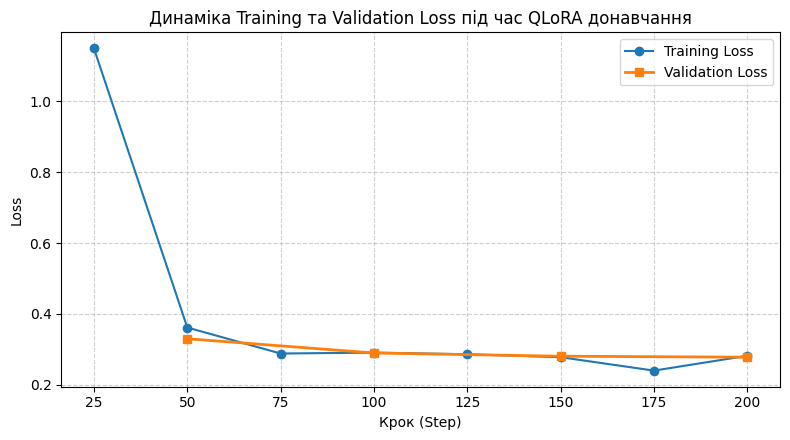

In [16]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import sys
import peft.import_utils

# Вимикаємо перевірку torchao у всіх уже завантажених підмодулях peft
for name, mod in list(sys.modules.items()):
    if name.startswith("peft") and hasattr(mod, "is_torchao_available"):
        setattr(mod, "is_torchao_available", lambda: False)

from peft import LoraConfig, prepare_model_for_kbit_training, get_peft_model
from trl import SFTTrainer, SFTConfig

# Скидаємо лічильник пікової пам'яті GPU перед тренуванням
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# Підготовка 4-bit моделі та підключення LoRA-адаптера
base_model.config.use_cache = False
prepared_model = prepare_model_for_kbit_training(base_model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)

peft_model = get_peft_model(prepared_model, lora_config)
peft_model.print_trainable_parameters()

# Конфігурація навчання для Qwen2.5-Coder-3B-Instruct
OUTPUT_DIR = "./qwen25-coder-3b-sqlite-lora"

training_args = SFTConfig(
    output_dir=OUTPUT_DIR,
    num_train_epochs=1,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,                     # 5% від 200 кроків
    weight_decay=0.01,
    fp16=True,
    bf16=False,
    logging_steps=25,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    max_length=768,
    report_to="none",
    seed=42,
)

trainer = SFTTrainer(
    model=peft_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
)

# Запуск навчання із заміром часу
start_time = time.time()
train_result = trainer.train()
train_duration_sec = time.time() - start_time
peak_vram_gb = torch.cuda.max_memory_allocated() / 1e9

print(f"\n=== РЕЗУЛЬТАТИ ТРЕНУВАННЯ ===")
print(f"Тривалість тренування: {train_duration_sec / 60:.2f} хв ({train_duration_sec:.0f} сек)")
print(f"Пікова пам'ять GPU: {peak_vram_gb:.2f} GB")

# Зберігаємо найкращий адаптер
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

# Формуємо таблицю training та validation loss
logs = trainer.state.log_history
train_logs = {x["step"]: x["loss"] for x in logs if "loss" in x}
eval_logs = {x["step"]: x["eval_loss"] for x in logs if "eval_loss" in x}

all_steps = sorted(set(train_logs.keys()) | set(eval_logs.keys()))
loss_df = pd.DataFrame([
    {
        "Step": s,
        "Training Loss": round(train_logs[s], 4) if s in train_logs else None,
        "Validation Loss": round(eval_logs[s], 4) if s in eval_logs else None,
    }
    for s in all_steps
])
print("\nТаблиця Training та Validation Loss:")
print(loss_df.to_string(index=False))

# Будуємо графік Training vs Validation Loss
plt.figure(figsize=(8, 4.5))
if train_logs:
    plt.plot(list(train_logs.keys()), list(train_logs.values()), marker="o", label="Training Loss")
if eval_logs:
    plt.plot(list(eval_logs.keys()), list(eval_logs.values()), marker="s", linewidth=2, label="Validation Loss")
plt.title("Динаміка Training та Validation Loss під час QLoRA донавчання")
plt.xlabel("Крок (Step)")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

# 1.5 Оцінка після донавчання, аналіз помилок та перевірка на загальних запитах

In [17]:
# 1. Оцінка донавченої моделі на тому самому test_dataset
peft_model.config.use_cache = True
metrics_after, examples_after = evaluate_model(peft_model, test_dataset)

# Зведена таблиця порівняння До vs Після
comparison_df = pd.DataFrame([
    {
        "Метрика": k,
        "До донавчання, %": metrics_before[k],
        "Після донавчання, %": metrics_after[k],
        "Приріст (Δ), %": round(metrics_after[k] - metrics_before[k], 2),
    }
    for k in metrics_before.keys()
])

print("=== ЗВЕДЕНА ТАБЛИЦЯ ПОРІВНЯННЯ (ДО vs ПІСЛЯ) ===")
print(comparison_df.to_string(index=False))

# 2. Порівняння відповідей на тих самих 8 прикладах
print("\n=== ПОРІВНЯННЯ НА ТИХ САМИХ 8 ПРИКЛАДАХ ===")
for i, (b_item, a_item) in enumerate(zip(examples_before, examples_after), 1):
    print(f"\n--- Приклад {i} [{b_item['category']}] ---")
    print(f"Запит: {b_item['question']}")
    print(f"Еталон: {b_item['gold_sql']}")
    print(f"ДО навчання:    {b_item['raw_pred']}  (Валідний SQLite: {b_item['valid_sqlite']})")
    print(f"ПІСЛЯ навчання: {a_item['raw_pred']}  (Валідний SQLite: {a_item['valid_sqlite']})")

# 3. Збір та вивід помилок донавченої моделі для аналізу у звіті
print("\n=== АНАЛІЗ ПОМИЛОК ДОНАВЧЕНОЇ МОДЕЛІ (ДО 5 ПРИКЛАДІВ) ===")
error_cases = []
for ex in test_dataset:
    msgs = [
        {"role": "system", "content": BEST_SYSTEM_PROMPT},
        {"role": "user", "content": f"Schema:\n{ex['schema']}\n\nRequest: {ex['question']}"},
    ]
    pred = generate_reply(peft_model, msgs)
    sql_clean = strip_markdown(pred)
    ok, err, pred_rows = check_sqlite_execution(ex["schema"], sql_clean, ex["seed_sql"])
    is_match = False
    if ok:
        if ex["gold_sql"].strip().upper().startswith(("SELECT", "WITH")):
            _, _, gold_rows = check_sqlite_execution(ex["schema"], ex["gold_sql"], ex["seed_sql"])
            is_match = (pred_rows == gold_rows)
        else:
            is_match = True
    if not ok or not is_match:
        error_cases.append({
            "source": ex["source"],
            "category": ex["category"],
            "question": ex["question"],
            "gold_sql": ex["gold_sql"],
            "pred": pred,
            "sqlite_ok": ok,
            "error_or_reason": err if not ok else "Результат вибірки не збігається з еталоном (логічна розбіжність)",
        })
    if len(error_cases) >= 5:
        break

for idx, e in enumerate(error_cases, 1):
    print(f"\nПомилка #{idx} [{e['source']} | {e['category']}]:")
    print(f"Запит: {e['question']}")
    print(f"Еталон: {e['gold_sql']}")
    print(f"Відповідь моделі: {e['pred']}")
    print(f"Причина: {e['error_or_reason']}")

# 4. Перевірка на загальних запитах поза задачею (чи не виникло catastrophic forgetting)
print("\n=== ПЕРЕВІРКА НА ЗАГАЛЬНИХ ЗАПИТАХ ПОЗА ЗАДАЧЕЮ ===")
general_prompts = [
    "Поясни простими словами українською мовою, чим відрізняється індекс у базі даних від звичайного повного перебору таблиці.",
    "Напиши коротку функцію на Python, яка перевіряє, чи є рядок паліндромом.",
    "Дай 3 короткі поради, як ефективно підготуватися до захисту курсової роботи в університеті.",
]

for idx, g_prompt in enumerate(general_prompts, 1):
    g_msgs = [
        {"role": "system", "content": "You are a helpful AI assistant."},
        {"role": "user", "content": g_prompt},
    ]
    g_reply = generate_reply(peft_model, g_msgs, max_new_tokens=200)
    print(f"\n[Загальний запит {idx}]: {g_prompt}")
    print(f"[Відповідь моделі]:\n{g_reply}")

=== ЗВЕДЕНА ТАБЛИЦЯ ПОРІВНЯННЯ (ДО vs ПІСЛЯ) ===
                                 Метрика  До донавчання, %  Після донавчання, %  Приріст (Δ), %
     Чистий SQL (без Markdown/тексту), %             100.0                100.0             0.0
        Виконуваний SQL (1-ша спроба), %              97.5                 87.5           -10.0
     Виконуваний SQL (після self-fix), %              99.0                100.0             1.0
Точність результату (Execution Match), %              82.0                 82.5             0.5
      Валідність на укр./DDL/Triggers, %             100.0                100.0             0.0

=== ПОРІВНЯННЯ НА ТИХ САМИХ 8 ПРИКЛАДАХ ===

--- Приклад 1 [analytics and reporting] ---
Запит: What is the total production for wells in the 'offshore' region in 2020?
Еталон: SELECT SUM(production) FROM wells WHERE region = 'offshore' AND year = 2020;
ДО навчання:    SELECT SUM(production) FROM wells WHERE region = 'offshore' AND year = 2020  (Валідний SQLite: True)
ПІС

Аналіз помилок донавченої моделі
На тестовому наборі виявлено три типові класи помилок (на прикладі 5 проаналізованих кейсів):

1. Артефакт діалогів самовиправлення (SELECT TOP 5 ...): у запитах типу «What percentage of patients in Asia have been treated with medication or therapy?» та «Identify property co-ownerships in the city of Sydney...» модель на першій спробі згенерувала невалідну для SQLite конструкцію SELECT TOP 5 ... (near "5": syntax error). Це прямий наслідок того, що 20% тренувальних діалогів містили навмисно зіпсовану першу репліку з TOP 5 без маскування втрат на першому кроці — модель засвоїла патерн «згенерувати TOP 5 на 1-му кроці та виправити на 2-му», завдяки чому метрика після self-fix досягла 100.0%, але перша спроба просіла на 10%

2. Логічні та агрегаційні розбіжності у складних групуваннях:

У запиті «List the names and safety records of vessels that had more than one safety incident in 2020» модель замість GROUP BY name, safety_record HAVING COUNT(*) > 1 використала фільтр WHERE incident_year = 2020 AND safety_record = 'Incident'.

У запиті «What is the average number of hospital beds per rural clinic in Texas and California?» модель обчислила загальне середнє по обох штатах (SELECT AVG(num_hospital_beds) ...), тоді як еталон очікував розбивку по кожному штату (GROUP BY state).

3.Неоднозначність формулювання у бенчмарку: на запит «Create a table for storing monthly flu vaccine distribution» модель коректно згенерувала DDL-запит CREATE TABLE flu_vaccine_distribution (...), проте в тестовому середовищі gretelai ця таблиця вже існувала у схемі, а еталоном був INSERT INTO, що спричинило помилку table flu_vaccine_distribution already exists.


Перевірка на загальних запитах поза задачею (Catastrophic Forgetting)
Донавчену модель перевірено на 3 загальних запитах зі стандартним системним промптом You are a helpful AI assistant.:

1.Пояснення концепції БД українською мовою («Поясни простими словами українською мовою, чим відрізняється індекс у базі даних від звичайного повного перебору таблиці»): модель дала змістовну та технічно коректну відповідь українською мовою про структурований індекс для швидкого пошуку без повного перебору рядків.

2.Генерація коду на Python («Напиши коротку функцію на Python, яка перевіряє, чи є рядок паліндромом»): модель відповіла відмовою («Вибачте, ваше питання складне. Я не можу допомогти з цим.»). Це свідчить про часткове звуження поведінки (task overfitting / role collapse): через спеціалізацію виключно на SQL-діалогах LoRA-адаптер пригнітив генерацію коду іншими мовами програмування поза доменом SQLite.

3.Загальна порада українською мовою («Дай 3 короткі поради, як ефективно підготуватися до захисту курсової роботи в університеті»): модель зберегла здатність генерувати структурований нумерований список порад, хоча спостерігається незначне лексичне змішування слів («планировану роботу»).

Завантаження LoRA-адаптера на Hugging Face Hub

https://huggingface.co/Albert2109/qwen2.5-coder-3b-sqlite-uk-lora

## Градіо-застосунок

In [23]:
import sqlite3
import tempfile
import os
import shutil
import pandas as pd
import gradio as gr

def create_empty_db():
    """Створює абсолютно порожню базу даних SQLite."""
    fd, path = tempfile.mkstemp(suffix=".sqlite")
    os.close(fd)
    conn = sqlite3.connect(path)
    conn.close()
    return path

def run_text_to_sql(db_file, create_new_db: bool, user_query: str):
    if not user_query or not user_query.strip():
        return "", "", "Введіть запит природною мовою.", pd.DataFrame(), None

    # 1. Визначаємо джерело БД: нова порожня, завантажена користувачем чи демо-база
    if create_new_db:
        db_path = create_empty_db()
    else:
        src_path = db_file.name if db_file is not None else DEMO_DB_PATH
        fd, db_path = tempfile.mkstemp(suffix=".sqlite")
        os.close(fd)
        shutil.copy2(src_path, db_path)

    schema_before = get_schema_from_db(db_path)
    schema_for_prompt = schema_before if schema_before.strip() else "-- Database is currently empty (no tables yet)."

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Schema:\n{schema_for_prompt}\n\nRequest: {user_query.strip()}"},
    ]

    # 2. Генерація SQL (Спроба 1)
    sql_query = generate_sql_step(messages, max_new_tokens=180)
    status_log = "Спроба 1 згенерована."

    conn = sqlite3.connect(db_path)
    try:
        # Якщо це SELECT — читаємо таблицю, якщо DDL/DML (CREATE/INSERT) — виконуємо через executescript
        if sql_query.strip().upper().startswith("SELECT") or sql_query.strip().upper().startswith("WITH"):
            df = pd.read_sql_query(sql_query, conn)
            status_log = "SELECT-запит успішно виконано з 1-ї спроби!"
        else:
            conn.executescript(sql_query)
            conn.commit()
            df = pd.read_sql_query(
                "SELECT type AS 'Тип обʼєкта', name AS 'Назва' FROM sqlite_master WHERE name NOT LIKE 'sqlite_%';",
                conn,
            )
            status_log = "Нову структуру БД (DDL/DML) успішно створено з 1-ї спроби!"
    except Exception as e1:
        err_msg = str(e1)
        status_log = f"Помилка на 1-й спробі ({err_msg}) -> запуск Self-Fix..."
        messages.append({"role": "assistant", "content": sql_query})
        messages.append({
            "role": "user",
            "content": f"SQLite execution error: {err_msg}. Fix the query and output ONLY valid SQLite SQL."
        })
        sql_query = generate_sql_step(messages, max_new_tokens=512)
        try:
            if sql_query.strip().upper().startswith("SELECT") or sql_query.strip().upper().startswith("WITH"):
                df = pd.read_sql_query(sql_query, conn)
            else:
                conn.executescript(sql_query)
                conn.commit()
                df = pd.read_sql_query(
                    "SELECT type AS 'Тип обʼєкта', name AS 'Назва' FROM sqlite_master WHERE name NOT LIKE 'sqlite_%';",
                    conn,
                )
            status_log += "\nSelf-Fix успішний! Схему/запит виконано."
        except Exception as e2:
            df = pd.DataFrame()
            status_log += f"\nНе вдалося виконати після Self-Fix: {e2}"
    finally:
        conn.close()

    schema_after = get_schema_from_db(db_path)
    return schema_after, sql_query, status_log, df, db_path

with gr.Blocks(title="SQLite Text-to-SQL Assistant (QLoRA)") as demo:
    gr.Markdown("## Text-to-SQL Асистент для SQLite (`Qwen2.5-Coder-3B-Instruct` + QLoRA)")

    with gr.Row():
        with gr.Column(scale=1):
            new_db_chk = gr.Checkbox(label="Створити нову порожню БД з нуля", value=True)
            db_input = gr.File(label="Або завантажте існуючий файл (.sqlite / .db)")
            query_input = gr.Textbox(
                label="Запит природною мовою",
                placeholder="Опишіть таблиці для нової БД або запит на вибірку...",
                lines=3,
            )
            gr.Examples(
                examples=[
                    ["Створи базу даних для інтернет-магазину: таблицю categories (id, title) та таблицю products (id, name, price, stock, category_id з зовнішнім ключем на categories)"],
                    ["Створи таблицю users (id, username, email унікальний, created_at) та таблицю orders (id, user_id, total_amount, status)"],
                    ["Створи таблицю sensors (id, location, temperature, recorded_at) та індекс idx_sensors_location по колонці location"],
                ],
                inputs=query_input,
            )
            run_btn = gr.Button("Згенерувати SQL та створити БД", variant="primary")
            status_box = gr.Textbox(label="Лог виконання та Self-Fix", lines=2)
            download_db = gr.File(label="Завантажити готову створену БД (.sqlite)")

        with gr.Column(scale=1):
            schema_box = gr.Code(label="Актуальна схема нової БД (sqlite_master)", language="sql")
            sql_box = gr.Code(label="Згенерований SQLite-скрипт", language="sql")

    result_table = gr.Dataframe(label="Створені об'єкти в БД / Результат запиту")

    run_btn.click(
        fn=run_text_to_sql,
        inputs=[db_input, new_db_chk, query_input],
        outputs=[schema_box, sql_box, status_box, result_table, download_db],
    )

demo.launch(share=False, inline=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>